# Lezione 8 — Il nostro esperimento: possiamo rispondere a una domanda vera con i dati?
**Machine Learning for the Humanities · 19 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/08_modelli_di_lingua_progetto.ipynb)

**Metodo:** modelli di lingua (n-grammi). **Laboratorio:** i piccoli progetti di gruppo.

Nella prima parte costruiamo il più semplice dei **modelli di lingua**: un programma che, date alcune parole, prevede
quella successiva. È lo stesso compito di ChatGPT, in miniatura. Lo usiamo per **generare** testi "alla maniera di",
per **misurare la sorpresa** di un modello davanti a una frase e per **attribuire** un testo a un autore.

Nella seconda parte lavoriamo ai **progetti**: una domanda vera, dei dati, un metodo, un'ipotesi, e un'interpretazione onesta.

### Obiettivi di apprendimento
1. spiegare che cosa fa un modello di lingua: $P(\text{parola} \mid \text{parole precedenti})$;
2. costruire un modello a n-grammi e generare testo;
3. capire la **perplessità** come misura di sorpresa;
4. distinguere **creatività** e **memorizzazione** in un modello che genera;
5. progettare un piccolo esperimento con domanda, ipotesi ed esiti possibili.

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
import math
import random
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def tokenizza(testo):
    """Parole e segni di punteggiatura, in minuscolo: 'Che gioia!' → ['che', 'gioia', '!']"""
    return re.findall(r"\w+|[^\w\s]", testo.lower())

def ricomponi(tokens):
    testo = " ".join(tokens)
    testo = re.sub(r" ([,.;:!?»)])", r"\1", testo)
    return re.sub(r"([«(]) ", r"\1", testo)

OPERE = {"Collodi": "collodi_pinocchio.txt", "Manzoni": "manzoni_promessi_sposi.txt", "Dante": "dante_commedia.txt",
         "Leopardi": "leopardi_canti.txt", "Deledda": "deledda_dopo_il_divorzio.txt",
         "Pirandello": "pirandello_cavallo_nella_luna.txt", "Di Giacomo": "digiacomo_novelle_napolitane.txt"}
TOKENS = {autore: tokenizza(leggi_testo(f)) for autore, f in OPERE.items()}
for a, t in TOKENS.items():
    print(f"{a:>10}: {len(t):,} token")

   Collodi: 52,868 token
   Manzoni: 285,367 token
     Dante: 127,055 token
  Leopardi: 30,290 token
   Deledda: 73,906 token
Pirandello: 47,641 token
Di Giacomo: 84,104 token


## 1. Prevedere la parola successiva
Un **modello a n-grammi** guarda le ultime *n − 1* parole e conta che cosa veniva dopo, nel corpus, quelle stesse parole.
Con *n = 2* (bigrammi) guarda una parola; con *n = 3* (trigrammi) due. Che cosa viene dopo *"felice"* nei vari autori?

In [3]:
def addestra(tokens, n=3):
    """Conta, per ogni contesto di n-1 parole, quali parole vengono dopo e quante volte."""
    conteggi = defaultdict(Counter)
    for i in range(len(tokens) - n + 1):
        contesto = tuple(tokens[i:i + n - 1])
        conteggi[contesto][tokens[i + n - 1]] += 1
    return conteggi

def prossima_parola(modelli, contesto):
    """Usa il contesto più lungo che il modello conosce (se non lo conosce, ne usa uno più corto)."""
    for m in modelli:                                 # modelli: dal più lungo al più corto
        k = len(next(iter(m)))                         # lunghezza del contesto di questo modello
        ctx = tuple(contesto[-k:]) if k else tuple()
        if ctx in m:
            return m[ctx]
    return None

def genera(autore, inizio, n=3, lunghezza=40, seme=0):
    random.seed(seme)
    modelli = [addestra(TOKENS[autore], k) for k in range(n, 0, -1)]
    testo = tokenizza(inizio)
    for _ in range(lunghezza):
        candidati = prossima_parola(modelli, testo)
        parole_, pesi = zip(*candidati.items())
        testo.append(random.choices(parole_, weights=pesi)[0])   # estrazione proporzionale ai conteggi
    return ricomponi(testo)

In [4]:
for autore in ["Leopardi", "Manzoni", "Dante", "Collodi"]:
    m = addestra(TOKENS[autore], n=2)
    dopo = m.get(("felice",), Counter())
    print(f"{autore:>9} ({sum(dopo.values())} volte): dopo 'felice' →", dopo.most_common(5))

 Leopardi (15 volte): dopo 'felice' → [(',', 3), ('in', 2), ('e', 2), ('sarei', 2), ('estimo', 1)]


  Manzoni (15 volte): dopo 'felice' → [(',', 5), ('di', 2), (';', 1), ('casati', 1), ('n', 1)]


    Dante (11 volte): dopo 'felice' → [(',', 2), ('!', 2), ('colui', 1), ('ne', 1), ('te', 1)]
  Collodi (2 volte): dopo 'felice' → [(',', 1), ('.', 1)]


Le parole felici sono **rare**: il modello di Collodi ha visto *felice* due volte. Le sue "previsioni" si basano su pochissimi
esempi, e la continuazione più probabile è spesso un segno di punteggiatura. Con una parola frequente va meglio:

In [5]:
m = addestra(TOKENS["Collodi"], n=2)
dopo = m[("burattino",)]
totale = sum(dopo.values())
print("P(parola | 'burattino') nel modello di Collodi:")
for parola, c in dopo.most_common(8):
    print(f"   {parola:>10}  {c / totale:.2f}")

P(parola | 'burattino') nel modello di Collodi:
            ,  0.24
            .  0.14
            e  0.05
            —  0.05
           di  0.04
            :  0.03
            !  0.02
          per  0.02


## 2. Generare testo
Per generare, estraiamo la parola successiva **a caso**, ma con probabilità proporzionale ai conteggi; poi ripetiamo.
Il `seme` fissa il caso: stesso seme, stesso testo.

In [6]:
for autore in ["Collodi", "Dante", "Leopardi", "Manzoni"]:
    print(f"— {autore} —")
    print(genera(autore, "la felicità", n=3, lunghezza=35, seme=1), "\n")

— Collodi —


la felicità! — il povero burattino mezzo morto. in quel paese non somigliava a tutti i ragazzi svogliati, che era cieco, si avvicinò al gatto: — in questo mondo, come se 

— Dante —


la felicità, non sofferse; e sì mirando in quelle parti calde d ’ un nomar un altro circumcinto, e ’ l punir di lor trarresi avante per abbracciarmi con sì diversa cennamella cavalier vidi 

— Leopardi —
la felicità non rise al viver nostro; e sì gli scava con le macchine al cielo emulatrici crebbero, e non può la lieta nonadecima età più bella a noi di lieti inganni e di cittadi 

— Manzoni —


la felicità terrena. privata così della sua barba che tutta la testa alta, compose la faccia mutata, almeno nel principale; ma che, in quella maniera, da quel gran soccorso, apriva 



I testi "suonano" come l'autore per qualche parola, poi perdono il filo: il modello vede solo **due parole** indietro.
E siccome *"la felicità"* è quasi assente dal corpus, all'inizio il modello deve ripiegare su un contesto più corto (solo *felicità*).
ChatGPT fa la stessa cosa, ma guarda indietro **migliaia** di parole e, invece di contare, usa una rete neurale addestrata su
una quantità enorme di testi.

## 3. Creatività o memorizzazione?
Un modello che genera **inventa** o **ricopia**? Misuriamo la sequenza più lunga del testo generato che compare
*identica* nel corpus di addestramento.

In [7]:
def copia_piu_lunga(generato, autore, massimo=25):
    gen, corpus = tokenizza(generato), TOKENS[autore]
    for L in range(min(massimo, len(gen)), 0, -1):
        visti = {tuple(corpus[i:i + L]) for i in range(len(corpus) - L + 1)}
        for i in range(len(gen) - L + 1):
            if tuple(gen[i:i + L]) in visti:
                return L, ricomponi(gen[i:i + L])
    return 0, ""

for n in [2, 3, 4]:
    testo = genera("Leopardi", "la felicità", n=n, lunghezza=30, seme=3)
    L, pezzo = copia_piu_lunga(testo, "Leopardi")
    print(f"n={n}: copia più lunga = {L} token → «{pezzo}»")

n=2: copia più lunga = 4 token → «dolci corde susurravano ancora»


n=3: copia più lunga = 7 token → «m ' inspiri o nascondendo il viso»
n=4: copia più lunga = 25 token → «di giorno in giorno dura. la bella speme tutti ci nutrica di sembianze beate. onde ciascuno indarno s ' affatica: altri l»


Più lungo è il contesto, più il modello **ricopia** il corpus: con pochi dati, un contesto lungo è stato visto una volta sola,
e allora c'è una sola continuazione possibile. Anche i grandi modelli possono **memorizzare** frasi intere dei loro dati
(per esempio testi protetti da copyright, o dati personali): è una delle grandi questioni etiche e legali del momento.

## 4. La perplessità: quanto è sorpreso un modello?
Un modello di lingua assegna una **probabilità** a ogni frase. La **perplessità** traduce quella probabilità in un numero
intuitivo: *quante parole, in media, il modello considera plausibili a ogni passo*. Bassa = poca sorpresa, il testo "gli suona familiare".

Per non dare probabilità zero alle coppie mai viste usiamo una **lisciatura** (*add-k*): aggiungiamo un piccolo conteggio a tutto.

In [8]:
VOCAB_COMUNE = set().union(*[set(t) for t in TOKENS.values()])

class Bigrammi:
    """Modello di bigrammi con lisciatura 'add-k': nessuna parola ha probabilità zero."""
    def __init__(self, tokens, k=0.1):
        self.bi = Counter(zip(tokens, tokens[1:]))
        self.uni = Counter(tokens)
        self.k, self.V = k, len(VOCAB_COMUNE) + 1
    def prob(self, prec, parola):
        return (self.bi[(prec, parola)] + self.k) / (self.uni[prec] + self.k * self.V)
    def perplessita(self, testo):
        t = tokenizza(testo)
        logp = sum(math.log(self.prob(a, b)) for a, b in zip(t, t[1:]))
        return math.exp(-logp / max(len(t) - 1, 1))

In [9]:
modelli_bi = {a: Bigrammi(t) for a, t in TOKENS.items()}
prove = ["Nel mezzo del cammin di nostra vita mi ritrovai per una selva oscura.",
         "Il burattino si mise a piangere e a strillare.",
         "La felicità è un'app che si aggiorna ogni mattina."]
tab = pd.DataFrame({a: [m.perplessita(f) for f in prove] for a, m in modelli_bi.items()}, index=[f[:45] for f in prove])
tab.round(0)

,Collodi,Manzoni,Dante,Leopardi,Deledda,Pirandello,Di Giacomo
Nel mezzo del cammin di nostra vita mi ritrov,22816.0,11360.0,1652.0,13592.0,26246.0,30041.0,19633.0
Il burattino si mise a piangere e a strillare,993.0,3303.0,5931.0,43909.0,4339.0,7671.0,2394.0
La felicità è un'app che si aggiorna ogni mat,6394.0,4158.0,18412.0,16052.0,6024.0,6642.0,7869.0


Ogni frase sorprende meno il "suo" autore: Dante per l'incipit della Commedia, Collodi per il burattino. La frase moderna
sorprende tutti; il meno sorpreso è Manzoni, che è anche il modello addestrato su più testo (e quindi abituato a più combinazioni).

## 5. Attribuire un testo con un modello di lingua
Se ogni autore ha il suo modello, possiamo attribuire una frase all'autore **meno sorpreso**. Addestriamo su 90% di ogni opera
e verifichiamo sul 10% finale (frasi mai viste). Usiamo i cinque prosatori.

In [10]:
def frasi(tokens):
    out, cur = [], []
    for t in tokens:
        cur.append(t)
        if t in ".!?":
            if len(cur) >= 8:
                out.append(cur)
            cur = []
    return out

prosatori = ["Collodi", "Manzoni", "Deledda", "Pirandello", "Di Giacomo"]
addestramento, prova = {}, []
for a in prosatori:
    taglio = int(len(TOKENS[a]) * 0.9)
    addestramento[a] = Bigrammi(TOKENS[a][:taglio])
    for f in frasi(TOKENS[a][taglio:])[:100]:
        prova.append((a, ricomponi(f)))

giuste = 0
for vero, f in prova:
    previsto = min(prosatori, key=lambda a: addestramento[a].perplessita(f))
    giuste += previsto == vero
print(f"Attribuzione con i modelli di lingua: {giuste}/{len(prova)} = {giuste / len(prova):.0%}  (a caso: 20%)")

Attribuzione con i modelli di lingua: 286/500 = 57%  (a caso: 20%)


Un risultato un po' inferiore alla SVM su frasi singole della lezione 4 (circa 66%), ottenuto con un'idea completamente diversa: invece di imparare un confine tra autori,
impariamo **come scrive ciascuno** e chiediamo chi avrebbe scritto più facilmente questa frase.

---
# Parte 2 — Laboratorio: i progetti di gruppo

## 6. Com'è fatto un buon progetto
Un piccolo progetto di *machine learning for the humanities* ha sei passi. Il nostro lessico della felicità offre una parola
per lo stato d'animo giusto di ciascuno (e per capire quale manca, quando un progetto si blocca):

| Passo | La domanda da farsi | La felicità giusta |
|---|---|---|
| **Domanda** | Che cosa voglio sapere, e perché interessa a un umanista? | *prīti* (sanscrito): l'entusiasmo dell'inizio, quando la domanda non è ancora risolta; *Vorfreude*, la gioia dell'attesa |
| **Dati** | Quali testi? Quanti? Rappresentano ciò che voglio studiare? | *manzoku* (giapponese): la soddisfazione della sufficienza; *lagom*, la giusta misura |
| **Metodo** | Quale misura o modello? Qual è la baseline? | *sukha*: in origine il mozzo di una ruota che gira bene; un metodo infelice non è triste, *stride* |
| **Ipotesi** | Che cosa mi aspetto, prima di guardare i risultati? | *Glück* (tedesco): felicità e fortuna insieme, come quando si scommette su un'idea |
| **Esiti possibili** | Che cosa vorrebbe dire ciascun risultato, anche quello che smentisce l'ipotesi? | *muditā*: la gioia per la fortuna degli altri, anche quando ha ragione l'ipotesi rivale |
| **Interpretazione** | Che cosa posso affermare, con quali limiti? | *ṭumaʾnīna* (arabo): il cuore in pace, quando una lettura regge e non serve più litigarci |

E per il progetto nel suo insieme: *eudaimonia*, una ricerca che va bene nel complesso, anche se non ogni giorno è felice.

## 7. Un mini-progetto svolto: la felicità di Pinocchio cresce verso il lieto fine?
**Domanda.** *Pinocchio* finisce bene: il burattino diventa un ragazzo. Il lessico della felicità cresce verso la fine?

**Dati.** I 36 capitoli; per ognuno le parole felici ogni 1000 (sei famiglie, 35 forme).

**Ipotesi.** La felicità lessicale cresce con il numero del capitolo.

**Esiti possibili.** (a) cresce: il lieto fine si prepara anche nel lessico; (b) non cresce: la felicità è distribuita, o arriva
tutta alla fine; (c) cresce ma per caso: con 36 capitoli una pendenza positiva può uscire anche a caso.

Pendenza osservata: -0.002 parole felici ogni 1000, per capitolo


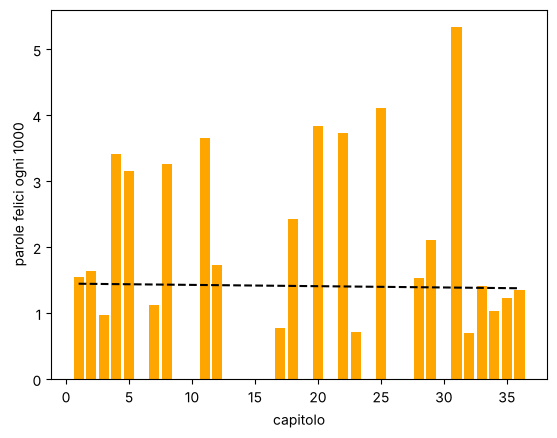

In [11]:
famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = set(famiglie["forma"])
cap = pd.read_csv(DATI / "pinocchio_capitoli.csv")
cap["parole"] = cap["testo"].apply(lambda t: len(re.findall(r"\w+", t)))
cap["felici"] = cap["testo"].apply(lambda t: sum(w in FORME_FELICI for w in re.findall(r"\w+", t.lower())))
cap["felici_1000"] = cap["felici"] / cap["parole"] * 1000

pendenza = np.polyfit(cap["capitolo"], cap["felici_1000"], 1)[0]
print(f"Pendenza osservata: {pendenza:+.3f} parole felici ogni 1000, per capitolo")

plt.bar(cap["capitolo"], cap["felici_1000"], color="orange")
plt.plot(cap["capitolo"], np.polyval(np.polyfit(cap["capitolo"], cap["felici_1000"], 1), cap["capitolo"]), "k--")
plt.xlabel("capitolo"); plt.ylabel("parole felici ogni 1000"); plt.show()

### Il risultato potrebbe essere un caso? Il test di permutazione
Idea semplice e potente: **mescoliamo a caso l'ordine dei capitoli** mille volte e calcoliamo ogni volta la pendenza.
Se pendenze come la nostra escono spesso anche nel disordine, il nostro risultato non dimostra niente.

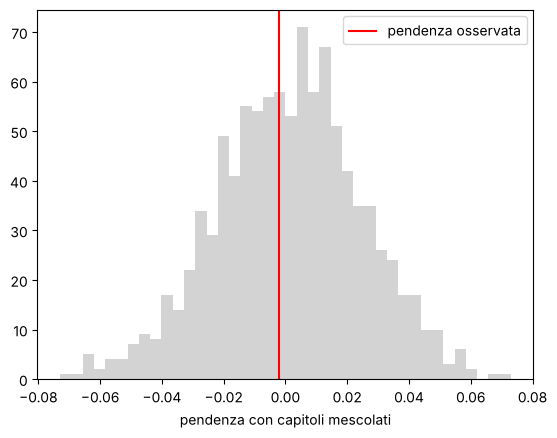

In 55.2% dei mescolamenti la pendenza è almeno quella osservata.


In [12]:
rng = np.random.default_rng(0)
pendenze_casuali = [np.polyfit(cap["capitolo"], rng.permutation(cap["felici_1000"]), 1)[0] for _ in range(1000)]
p = np.mean(np.array(pendenze_casuali) >= pendenza)
plt.hist(pendenze_casuali, bins=40, color="lightgray")
plt.axvline(pendenza, color="red", label="pendenza osservata")
plt.legend(); plt.xlabel("pendenza con capitoli mescolati"); plt.show()
print(f"In {p:.1%} dei mescolamenti la pendenza è almeno quella osservata.")

**Interpretazione.** La pendenza è praticamente **zero**, e più di metà dei mescolamenti casuali dà una pendenza uguale o
maggiore: **non c'è alcuna crescita** della felicità lessicale verso il lieto fine. (Di solito si considera "difficile da
spiegare con il caso" un risultato che esce in meno del 5% dei mescolamenti.) È un risultato negativo, ed è un risultato vero. Ricordiamo anche (lezione 2) che il capitolo più "felice" è quello del Paese dei balocchi:
in Collodi la *contentezza* è spesso il preludio del guaio. Un buon progetto può partire proprio da qui: *come* Collodi usa
la felicità, invece di *quanta* ne usa.

## 8. Idee per i progetti (i dati sono già nella cartella `data/`)
1. **La letizia di Dante.** La felicità cresce anche *dentro* il Paradiso, canto per canto? E nel Purgatorio?
2. **Leopardi e la felicità negata.** Quante volte *felice/felicità* è preceduta da una negazione (*non, né, mai*) nei *Canti*?
3. **Chi è contento?** Nei *Promessi sposi*, quali personaggi compaiono vicino alle parole felici (finestra di 10 parole)?
4. **Umorismo e novelle.** Il saggio *L'umorismo* e le novelle di Pirandello: un classificatore distingue saggio e narrativa? Con quali parole?
5. **Napoli e la Sardegna.** Di Giacomo e Deledda: cluster e parole distintive di due Italie regionali.
6. **Imitare un autore.** Un modello di lingua di Collodi genera "Pinocchio"? Come lo valutiamo (perplessità, copie, lettori umani)?
7. **Il lessico della felicità in altre lingue.** Partendo da `lessico_felicita.csv`: quali sfumature del lessico (per esempio
   *Vorfreude*, l'attesa) si ritrovano nei testi italiani, e con quali parole?

**Checklist prima di presentare (20 novembre):** domanda in una frase · dati descritti (quanti testi, quali, perché) · baseline ·
almeno un grafico · un risultato *e* i suoi limiti · che cosa fareste con più tempo.

## Esercizi
Soluzioni in `solutions/08_modelli_di_lingua_progetto_soluzioni.ipynb`.

**Esercizio 1 — Generare e controllare.** Generate tre testi da 40 token con il modello di Dante, con `n=2`, `n=3` e `n=4`.
Per ognuno misurate la copia più lunga dal corpus. Quale vi sembra più "dantesco"? Quale più originale? Sono la stessa cosa?

**Esercizio 2 — Chi è meno sorpreso?** Scrivete quattro frasi: una "alla Collodi", una "alla Manzoni", una "alla Leopardi" e una
moderna. Calcolate la perplessità di ognuna con i sette modelli `modelli_bi`. L'autore meno sorpreso è quello che vi aspettavate?

**Esercizio 3 — Il vostro progetto.** Compilate per il vostro gruppo le sei voci del progetto (domanda, dati, metodo, ipotesi,
esiti possibili, interpretazione attesa) in una cella di testo, e scrivete il codice per il **primo passo** (caricare i dati e fare
un primo conteggio o grafico).

In [13]:
# Esercizio 1

In [14]:
# Esercizio 2

**Esercizio 3 — Il nostro progetto**
- **Domanda:**
- **Dati:**
- **Metodo (e baseline):**
- **Ipotesi:**
- **Esiti possibili:**
- **Interpretazione attesa e limiti:**

In [15]:
# Esercizio 3: primo passo